# AgentAccess

**Authors:** Alexander Michels

In [1]:
import access
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess

In [2]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [3]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

66


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


In [4]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car.head()

,origin,destination,minutes
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [5]:
time_steps = 10

In [6]:
# intialize our model
# def __init__(self, demand_df, demand_geoid, demand_field, supply_df, supply_geoid, supply_field,
#              cost_df, cost_origin, cost_dest, cost_field, time_steps, memory=0, pop_per_agent=1000, top_k=0):
model = AgentAccess(
    pop,
    "FIPS",
    "E_TOTPOP",
    hos,
    "who cares",
    "BEDS",
    car,
    "origin",
    "destination",
    "minutes",
    time_steps,
    output_path="../outputs/"
)

Running Model: 100%|██████████| 10/10 [02:44<00:00, 16.45s/it]


In [7]:
model.supply_df.head()

,geometry,Supply,Demand 0,Ratio 0,Demand 1,Ratio 1,Demand 2,Ratio 2,Demand 3,Ratio 3,...,Demand 5,Ratio 5,Demand 6,Ratio 6,Demand 7,Ratio 7,Demand 8,Ratio 8,Demand 9,Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031031000,"POLYGON ((-87.67441 41.97610, -87.66961 41.976...",189,62,3.000000,97,1.928571,88,2.123596,84,2.223529,...,81,2.304878,68,2.739130,93,2.010638,87,2.147727,92,2.032258
17031031300,"POLYGON ((-87.65499 41.97640, -87.65428 41.976...",115,56,2.017544,77,1.474359,67,1.691176,62,1.825397,...,70,1.619718,61,1.854839,73,1.554054,76,1.493506,70,1.619718
17031031400,"POLYGON ((-87.65012 41.96916, -87.64964 41.969...",184,56,3.228070,88,2.067416,83,2.190476,97,1.877551,...,82,2.216867,92,1.978495,92,1.978495,81,2.243902,76,2.389610
17031032100,"POLYGON ((-87.65634 41.96176, -87.65475 41.961...",134,59,2.233333,81,1.634146,76,1.740260,90,1.472527,...,76,1.740260,68,1.942029,77,1.717949,79,1.675000,73,1.810811
17031040300,"POLYGON ((-87.70582 41.98309, -87.70401 41.983...",279,99,2.790000,106,2.607477,100,2.762376,132,2.097744,...,128,2.162791,112,2.469027,126,2.196850,96,2.876289,96,2.876289


In [8]:
model.spatial_units_df.head()

,Demand,geometry,Ratio 0,Time 0,Ratio 1,Time 1,Ratio 2,Time 2,Ratio 3,Time 3,...,Ratio 5,Time 5,Ratio 6,Time 6,Ratio 7,Time 7,Ratio 8,Time 8,Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",2.744780,19.100000,1.402985,40.550000,4.165493,19.100,4.372951,19.630000,...,0.714286,10.730000,3.102041,24.370000,2.154762,36.050000,3.471831,25.450000,3.846667,16.300000
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",2.117647,36.270000,1.356322,30.430000,3.722581,46.880,3.607477,35.230000,...,3.781818,26.080000,1.691358,51.880000,3.311688,35.670000,4.457143,26.080000,2.214286,31.870000
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",3.450185,35.000000,6.275229,22.930000,1.666667,35.350,2.384615,42.270000,...,4.074380,31.770000,4.700441,25.370000,5.000000,53.220000,4.457143,49.980000,1.839080,18.550000
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",3.043654,7.537500,3.717436,24.035000,2.721506,28.725,2.743503,21.022500,...,2.703930,16.067500,3.028785,27.480000,2.929378,13.142500,3.245808,17.567500,2.884215,19.522500
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",3.472847,33.117143,3.192074,20.355714,2.797077,30.610,3.439317,28.394286,...,3.322749,18.224286,3.189917,18.994286,3.171281,17.247143,3.922232,24.848571,2.701827,19.367143


In [9]:
ratios = []
ratio_columns = [f"Ratio {x}" for x in range(time_steps)]
for index, row in model.supply_df.iterrows():
    ratios.append(list(row[ratio_columns]))

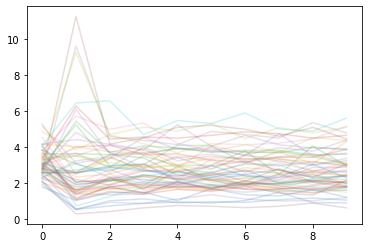

In [10]:
for i, index in enumerate(model.supply_df.index):
    plt.plot(range(time_steps), ratios[i], label=index, alpha=0.2)
ax = plt.gca()

In [11]:
ratios = []
ratio_columns = [f"Ratio {x}" for x in range(time_steps)]
for index, row in model.spatial_units_df.iterrows():
    ratios.append(list(row[ratio_columns]))

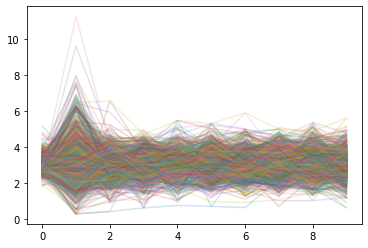

In [12]:
for i, index in enumerate(model.spatial_units_df.index):
    plt.plot(range(time_steps), ratios[i], label=index, alpha=0.2)

<AxesSubplot:>

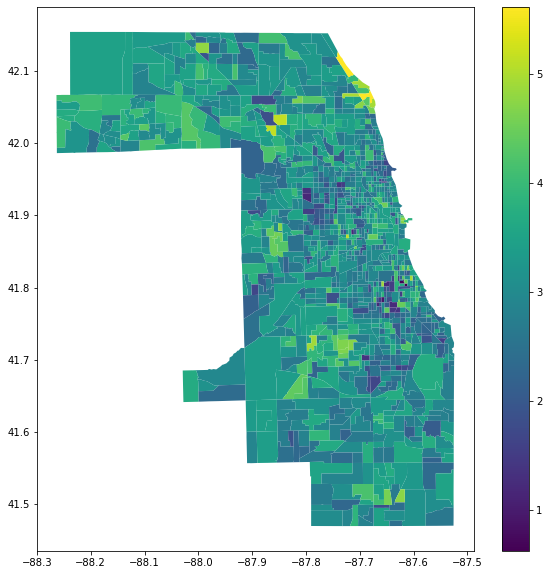

In [13]:
model.spatial_units_df.plot(column=f"Ratio {time_steps -1}", figsize=(10, 10), legend=True)

In [14]:
times = []
time_columns = [f"Time {x}" for x in range(time_steps)]
for index, row in model.spatial_units_df.iterrows():
    times.append(list(row[time_columns]))

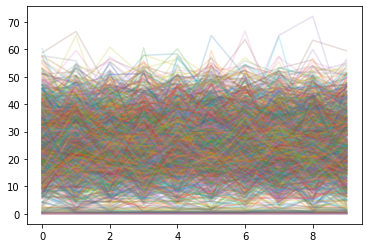

In [15]:
for i, index in enumerate(model.spatial_units_df.index):
    plt.plot(range(time_steps), times[i], label=index, alpha=0.2)

<AxesSubplot:>

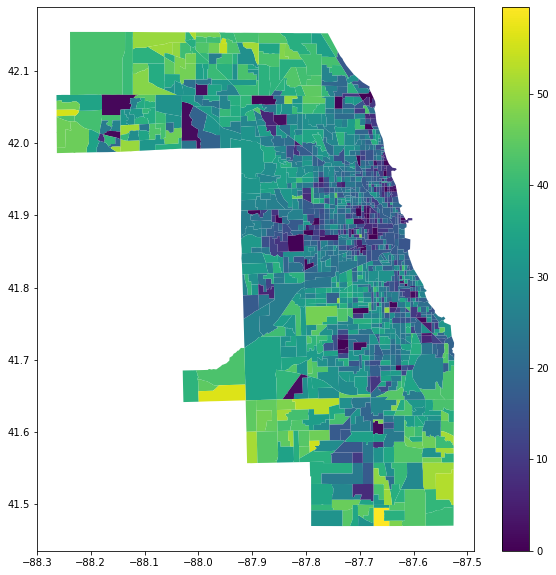

In [16]:
model.spatial_units_df.plot(column=f"Time {time_steps -1}", figsize=(10, 10), legend=True)

In [17]:
def normalize_columns(df, columns):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
    return df

<AxesSubplot:>

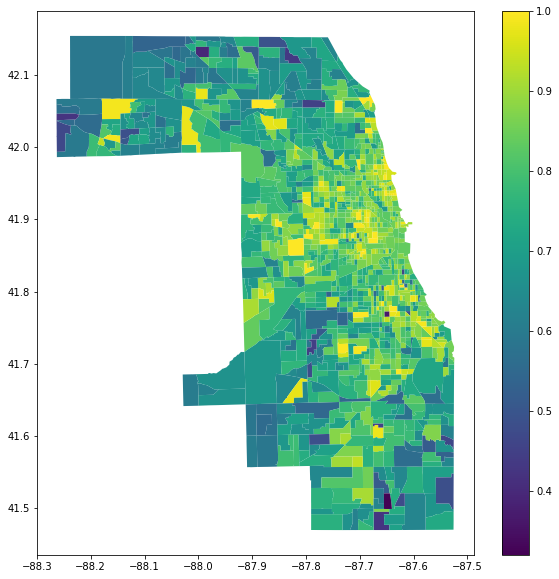

In [18]:
spatial_units_df = normalize_columns(model.spatial_units_df, [f"Time {time_steps -1}", f"Ratio {time_steps -1}"])
spatial_units_df["Product"] = (spatial_units_df[f"Time {time_steps -1}"] * spatial_units_df[f"Ratio {time_steps -1}"])
spatial_units_df["Product"] = 1 + (-1 * spatial_units_df["Product"])
spatial_units_df.plot(column="Product", figsize=(10, 10), legend=True)

In [22]:
# calculate the gravity-based access
A = access.Access(
    demand_df=pop,
    demand_index="FIPS",
    demand_value="E_TOTPOP",
    supply_df=model.supply_df,
    supply_index=True,
    supply_value="Supply",
    cost_df=car,
    cost_origin="origin",
    cost_dest="destination",
    cost_name="minutes"
)

In [23]:
gravity = access.weights.gravity(scale=60, alpha=-1, min_dist=1)
fn30 = access.weights.step_fn({10: 1, 20: 0.68, 30: 0.22})
fn60 = access.weights.step_fn({20: 1, 40: 0.68, 60: 0.22})
gaussian = access.weights.gaussian(20)

In [24]:
A.weighted_catchment(name="gravity", weight_fn=gravity)
# A.fca_ratio(name="fca", max_cost=15)
# A.fca_ratio(name="fca", max_cost=30) 
# A.fca_ratio(name="fca60", max_cost=60)
# A.fca_ratio(name="fca90", max_cost=90)
A.two_stage_fca(name="2sfca", max_cost=60)
A.enhanced_two_stage_fca(name="2sfca30", weight_fn=fn30)
A.enhanced_two_stage_fca(name="2sfca60", weight_fn=fn60)
A.enhanced_two_stage_fca(name="g2sfca", weight_fn=gaussian)
A.three_stage_fca(name="3sfca")
# A.raam(name="raam", tau=60)
# A.raam(name="raam30", tau=30)

,3sfca_Supply
FIPS,
17031010100,0.005337
17031010201,0.005148
17031010202,0.005539
17031010300,0.005940
17031010400,0.004095
...,...
17031843700,0.004093
17031843800,0.002721
17031843900,0.004008


In [25]:
A.access_df.head()

,E_TOTPOP,gravity_Supply,2sfca_Supply,2sfca30_Supply,2sfca60_Supply,g2sfca_Supply,3sfca_Supply
FIPS,,,,,,,
17031010100,4522,28947.351633,0.002790,0.003988,0.002484,0.002699,0.005337
17031010201,7039,30688.468786,0.003022,0.004222,0.002714,0.002867,0.005148
17031010202,2852,29613.408700,0.002956,0.004354,0.002645,0.002820,0.005539
17031010300,6650,29395.681764,0.002931,0.004445,0.002648,0.002814,0.005940
17031010400,5153,31556.255500,0.003050,0.002963,0.003023,0.003120,0.004095


In [27]:
spatial_units_df = spatial_units_df.merge(A.access_df, left_index=True, right_index=True)
spatial_units_df.head()

,Demand,geometry,Ratio 0,Time 0,Ratio 1,Time 1,Ratio 2,Time 2,Ratio 3,Time 3,...,Ratio 9,Time 9,Product,E_TOTPOP,gravity_Supply,2sfca_Supply,2sfca30_Supply,2sfca60_Supply,g2sfca_Supply,3sfca_Supply
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",2.744780,19.100000,1.402985,40.550000,4.165493,19.100,4.372951,19.630000,...,0.646304,0.274099,0.822849,0,39837.372655,0.003801,0.004707,0.004417,0.004737,0.003667
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",2.117647,36.270000,1.356322,30.430000,3.722581,46.880,3.607477,35.230000,...,0.318829,0.535923,0.829132,0,28311.101254,0.003613,0.000744,0.003538,0.002564,0.001266
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",3.450185,35.000000,6.275229,22.930000,1.666667,35.350,2.384615,42.270000,...,0.243559,0.311935,0.924026,0,33166.883503,0.003801,0.002793,0.003975,0.003692,0.002473
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",3.043654,7.537500,3.717436,24.035000,2.721506,28.725,2.743503,21.022500,...,0.453225,0.328289,0.851211,3836,31084.752206,0.003123,0.004222,0.002825,0.002925,0.004924
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",3.472847,33.117143,3.192074,20.355714,2.797077,30.610,3.439317,28.394286,...,0.416636,0.325676,0.864312,6739,30644.100285,0.003228,0.004036,0.003269,0.003030,0.004207


In [28]:
columns = [f"Ratio {time_steps-1}", f"Time {time_steps-1}", f"Product", "gravity_Supply", "2sfca_Supply", "2sfca30_Supply", "2sfca60_Supply", "g2sfca_Supply", "3sfca_Supply"]
corr = spatial_units_df[columns].corr()
corr.style.background_gradient(cmap='coolwarm')

,Ratio 9,Time 9,Product,gravity_Supply,2sfca_Supply,2sfca30_Supply,2sfca60_Supply,g2sfca_Supply,3sfca_Supply
Ratio 9,1.000000,0.137002,-0.531135,0.006125,-0.084958,0.065057,-0.078752,-0.035129,0.110244
Time 9,0.137002,1.000000,-0.874895,-0.644305,-0.440859,-0.536043,-0.499699,-0.536267,-0.547999
Product,-0.531135,-0.874895,1.000000,0.552988,0.393094,0.425462,0.445550,0.462515,0.418755
gravity_Supply,0.006125,-0.644305,0.552988,1.000000,0.673174,0.811063,0.792053,0.859635,0.604103
2sfca_Supply,-0.084958,-0.440859,0.393094,0.673174,1.000000,0.583306,0.909718,0.820181,0.329221
2sfca30_Supply,0.065057,-0.536043,0.425462,0.811063,0.583306,1.000000,0.769576,0.888566,0.791142
2sfca60_Supply,-0.078752,-0.499699,0.445550,0.792053,0.909718,0.769576,1.000000,0.960267,0.438506
g2sfca_Supply,-0.035129,-0.536267,0.462515,0.859635,0.820181,0.888566,0.960267,1.000000,0.553816
3sfca_Supply,0.110244,-0.547999,0.418755,0.604103,0.329221,0.791142,0.438506,0.553816,1.000000
